# Logistic Regression: Predicting Tumor Malignancy

In this notebook, we're building a clean and effective Logistic Regression model to classify breast cancer tumors. It's a great example of binary classification where understanding the difference between false positives and false negatives is extremely important.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Set a nice style for our plots
plt.style.use('ggplot')

## 1. Loading the Data
We are using the Breast Cancer Wisconsin dataset. To keep the model simple and prevent multicollinearity issues in standard logistic regression, we'll select a few key features that represent the tumor.

In [2]:
data = load_breast_cancer()

# Pick 3 simple features to keep the code easy to understand
features = ['mean radius', 'mean texture', 'mean smoothness']
df = pd.DataFrame(data.data, columns=data.feature_names)[features]

# Target: 0 means Malignant, 1 means Benign
df['TARGET'] = data.target  

print("Here is what our data looks like:")
display(df.head())

Here is what our data looks like:


,mean radius,mean texture,mean smoothness,TARGET
0,17.99,10.38,0.11840,0
1,20.57,17.77,0.08474,0
2,19.69,21.25,0.10960,0
3,11.42,20.38,0.14250,0
4,20.29,14.34,0.10030,0


## 2. Visual Exploratory Data Analysis (EDA)
Let's see if we can visually tell the difference between malignant and benign tumors based purely on their radius. A good model needs good separation in the data.

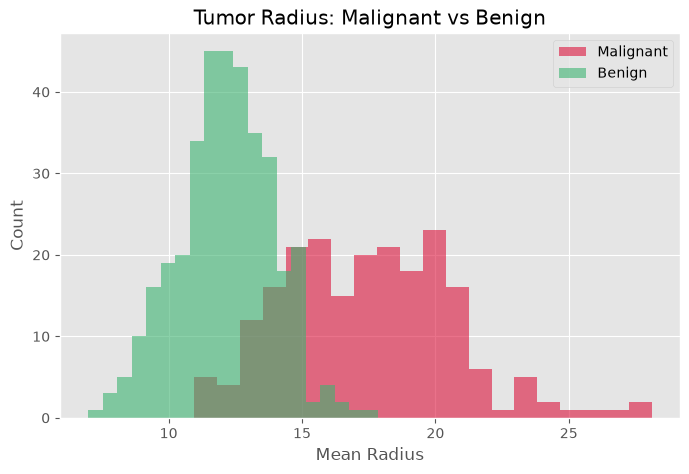

In [3]:
plt.figure(figsize=(8, 5))

# Plotting Malignant tumors (Target == 0)
plt.hist(df[df['TARGET']==0]['mean radius'], bins=20, alpha=0.6, color='crimson', label='Malignant')

# Plotting Benign tumors (Target == 1)
plt.hist(df[df['TARGET']==1]['mean radius'], bins=20, alpha=0.6, color='mediumseagreen', label='Benign')

plt.title('Tumor Radius: Malignant vs Benign')
plt.xlabel('Mean Radius')
plt.ylabel('Count')
plt.legend()
plt.show()

## 3. Training the Logistic Regression Model
We use `statsmodels` to train our model. It's powerful because it gives us a detailed statistical summary out-of-the-box.

In [4]:
# Separate features (X) and target (y)
X = df.drop('TARGET', axis=1)
X = sm.add_constant(X)  # Always add an intercept for regression!
y = df['TARGET']

# Split the data into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train the model
logit_model = sm.Logit(y_train, X_train).fit(disp=False)
print(logit_model.summary())

                           Logit Regression Results                           
Dep. Variable:                 TARGET   No. Observations:                  398
Model:                          Logit   Df Residuals:                      394
Method:                           MLE   Df Model:                            3
Date:                Mon, 28 Sep 2026   Pseudo R-squ.:                  0.7215
Time:                        16:20:20   Log-Likelihood:                -73.293
converged:                       True   LL-Null:                       -263.17
Covariance Type:            nonrobust   LLR p-value:                 5.352e-82
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              38.0241      4.531      8.393      0.000      29.144      46.904
mean radius        -1.2422      0.156     -7.971      0.000      -1.548      -0.937
mean texture       -0.3487      

## 4. Making Predictions & Evaluation
Logistic regression outputs a **probability** (a number between 0 and 1). We decide that if the probability is greater than 0.5, we classify it as Benign (1), otherwise Malignant (0).

We will evaluate this using a **Confusion Matrix**, which is much more valuable than simple accuracy because it shows us exactly *where* we made mistakes.

--- Classification Report ---
               precision    recall  f1-score   support

Malignant (0)       0.92      0.95      0.94        63
   Benign (1)       0.97      0.95      0.96       108

     accuracy                           0.95       171
    macro avg       0.95      0.95      0.95       171
 weighted avg       0.95      0.95      0.95       171



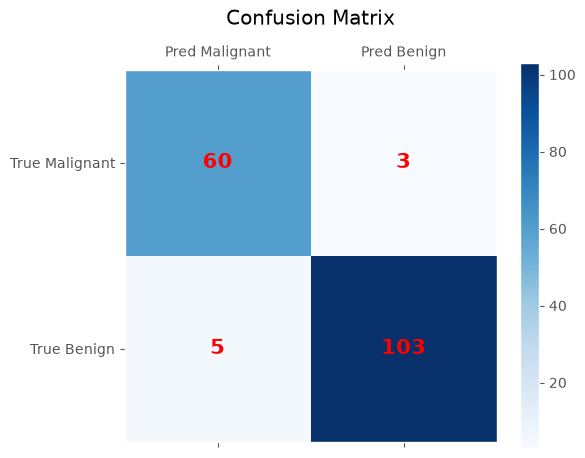

In [5]:
# Get probabilities
pred_probs = logit_model.predict(X_test)

# Convert probabilities to 0 or 1 classes
preds = (pred_probs > 0.5).astype(int)

print("--- Classification Report ---")
print(classification_report(y_test, preds, target_names=['Malignant (0)', 'Benign (1)']))

# Plotting the Confusion Matrix nicely
cm = confusion_matrix(y_test, preds)

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm, cmap='Blues')
plt.colorbar(cax)

# Add numbers into the matrix squares
for (i, j), val in np.ndenumerate(cm):
    ax.text(j, i, f'{val}', ha='center', va='center', color='red', fontsize=15, weight='bold')

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Pred Malignant', 'Pred Benign'])
ax.set_yticklabels(['True Malignant', 'True Benign'])
plt.title('Confusion Matrix', pad=15)
plt.grid(False)
plt.show()